# One KBM, many numerics: SPR-045 `kbm_free` sample_0818 against WIDTH and NBASIS (GFTM pointwise, GFTM Galerkin, TGLF)

Fusion_PhD-qp5.26. The single-mode version of the Latin-hypercube figures of `gftm_galerkin_field_width_selection.ipynb`
(qp5.24) and `gftm_quadrature_extent.ipynb` / `tglf_quadrature_extent.ipynb`: how the growth rate, frequency and
eigenfunction of one well-resolved GS2 KBM depend on the Hermite basis WIDTH $W$ and size $N$ (NBASIS).

**The mode.** SPR-045 `kbm_free` GS2 `sample_0818` (user's pick, 2026-11-01): $k_y\rho = 0.0198$, free parity, a clean KBM
under the user classifier ($T < 0.05$, $\omega > 0$, $0.25 < \chi_e/\chi_i < 4$; values printed below).

**Runs** (Fusion_PhD `results/spr045_single_kbm/`, GyroRun YAMLs): one leaf per arm under
`<CODE>/Runs/single_mode_spr045/SPR-045/`, each a cube of copies of this one GS2 deck in which only WIDTH / NBASIS
(/ NXGRID) change from run to run; the settings of every run are per-sample variables of its `pyroscan.nc`.
- GFTM `galF` (pointwise field solve, production) and `galT` (Galerkin, `FIELD_GALERKIN T`), both on the Galerkin build:
  NBASIS 2/4/8/16/32 at NXGRID 32 and 64 at NXGRID 65; FILTER 0.5, IBRANCH $-1$, NMODES 4 (as qp5.24).
- TGLF `fixed_width`: NBASIS_MAX 2/4/8/16/32, NXGRID 32, FILTER 0, THETA_TRAPPED 0.7, FIND_WIDTH F (as tglf_quadrature_extent).
- TGLF `find_width`: FIND_WIDTH T over 0.2–4.0, NBASIS_MIN 2/4/8/16/32, NBASIS_MAX 32 (as tglf_find_width part B).
- 47 widths: the 24-point `WIDTH_ORACLE_GRID` (0.2–4.0) and its geometric midpoints.

**Conventions.** Dominant mode = $\arg\max$ of the growth rate over `mode`; a run with no unstable mode has $\gamma = 0$.
pyro's $\omega > 0$ is the ion direction, for every code. Extent = pyro `Extent`, the $\theta$ range holding 95% of
$|\cdot|^2$; extent ratio = code / GS2. $B_\parallel$ is read with pyro PR #613 (`e2772bd`, not merged; re-saved
`pyroscan.nc` per leaf), because GyroRun's pinned pyro stores GFTM's raw $\sigma = \delta B_\parallel/(B k_\perp\rho)$;
`Fusion_PhD-38e9.30` (`results/gftm_bpar_extent`) shows the pointwise GFTM $B_\parallel$ extent fails at large $W$ for
numerical reasons that the Galerkin solve removes. GS2 holds $|\phi|^2$ only, so eigenfunctions are compared in modulus.

Advisory (agent analysis).

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pyrokinetics
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
PAPERS = ROOT.parent  # the Papers repo, when General_Analysis is its submodule
plt.style.use([ROOT / "src/general_analysis/paper.mplstyle", PAPERS / "styles/paper.mplstyle"])
W = plt.rcParams["figure.figsize"][0]  # paper \textwidth; figures are made at printed size
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "spr045_single_kbm"
sample = "sample_0818"
gs2_leaf = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2" / "Runs" / "LATIN_HYPERCUBE" / "SPR-045" / "kbm_free"
# GyroRun wrote this scan to the scratch tree
single_root = Path(os.environ["GYRO_DATA_OUTPUT"])
leaves = {"F": single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galF_sample_0818",
          "T": single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galT_sample_0818",
          "TGLF": single_root / "TGLF/Runs/single_mode_spr045/SPR-045/fixed_width_sample_0818"}
find_width_leaf = single_root / "TGLF/Runs/single_mode_spr045/SPR-045/find_width_sample_0818"
# the same leaves re-saved with the pyro #613 B_par reader (rebuild_bpar.py in Fusion_PhD results/spr045_single_kbm)
bpar_leaves = {arm: leaf.parent / "bpar613" / leaf.name for arm, leaf in leaves.items()}
arms = {"F": "GFTM pointwise", "T": "GFTM Galerkin", "TGLF": "TGLF"}
arm_colours = {"F": "C0", "T": "C3", "TGLF": "C2"}
nbasis_all = [2, 4, 8, 16, 32, 64]
fields = ["phi", "apar", "bpar"]
field_labels = {"phi": r"$\phi$", "apar": r"$A_\parallel$", "bpar": r"$B_\parallel$"}
fraction = 0.95                         # pyro Extent: theta range holding 95% of |field|^2
overshoot_tolerance = 0.10
fs_title = fs_legend = plt.rcParams["font.size"]


def log_xticks(ax, ticks):
    lims = ax.get_xlim()
    ax.set_xticks(ticks)
    ax.set_xlim(lims)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()

pyrokinetics 0.9.2.dev153+g3290c692


## GS2 reference: is sample_0818 a clean KBM?

The `kbm_free` cube, this sample only. Classifier quantities as in `docs/mode_filtering.md`: tearing parameter $T$
(saved by the cube), $\omega$ sign, and $\chi_e/\chi_i$ from the cube's heat and particle fluxes (the candidate script
`results/spr045_single_kbm/candidate_eigenfunctions.py` computed the same; its kbm_free species rule is repeated here).

In [2]:
gs2_scan = PyroHypercube(pyroscan_json=gs2_leaf / "pyroscan.json", load_base_pyro=True)
gs2_scan.load_gk_output(netcdf_file=gs2_leaf / "pyroscan.nc")
sample_index = list(gs2_scan.gk_output.data.sample_name.values.astype(str)).index(sample)
gs2_output = gs2_scan.gk_output.data.isel(sample=sample_index).pint.dequantify()

species = gs2_scan.sample_pyro(sample_index).local_species
ions = [name for name in species.names if name != "electron"]
# the kbm_free deck rule (docs/gyro_data_runs.md): ions share the first ion's a/L_T, every a/L_n is the electron's
for ion in ions:
    species[ion].inverse_ln = species.electron.inverse_ln
    species[ion].inverse_lt = species[ions[0]].inverse_lt
heat, particle = gs2_output.heat.sum("field"), gs2_output.particle.sum("field")
chi = lambda group: (sum(float(heat.sel(species=s)) - 1.5 * species[s].temp.m * float(particle.sel(species=s)) for s in group)
                     / sum(species[s].dens.m * species[s].temp.m * species[s].inverse_lt.m for s in group))

gamma_gs2, omega_gs2 = float(gs2_output.growth_rate), float(gs2_output.mode_frequency)
gs2_power = {field: gs2_output.eigenfunctions_squared.sel(field=field).isel(kx=0).dropna("theta") for field in fields}
extent_gs2 = {field: float(Extent._compute(power, fraction)[0]) for field, power in gs2_power.items()}
print(f"ky {float(gs2_output.ky):.4f} | gamma {gamma_gs2:.4f} | omega {omega_gs2:+.4f} | T {float(gs2_output.tearing_parameter):.1e} "
      f"| chi_e/chi_i {chi(['electron']) / chi(ions):.2f} | growth_rate_tolerance {float(gs2_output.growth_rate_tolerance):.1e} "
      f"| phi even fraction {float(gs2_output.phi_even_fraction):.3f}, apar {float(gs2_output.apar_even_fraction):.3f}")
theta_box = float(gs2_power["phi"].theta.max())
print("extent (rad):", {field: round(value, 3) for field, value in extent_gs2.items()}, "| theta box +-", round(theta_box, 2))
print("|phi| at the box edge / max:", float(np.sqrt(gs2_power["phi"][[0, -1]].max() / gs2_power["phi"].max())))

ky 0.0198 | gamma 1.3708 | omega +0.1760 | T 1.1e-11 | chi_e/chi_i 1.10 | growth_rate_tolerance 5.7e-05 | phi even fraction 1.000, apar 0.000
extent (rad): {'phi': 1.638, 'apar': 2.258, 'bpar': 1.549} | theta box +- 15.71
|phi| at the box edge / max: 9.375572006480374e-06


## Case slide: the mode and how it differs from the SPR-045 base deck

GS2 $|\phi|(\theta)$ and $|A_\parallel|(\theta)$ of sample_0818, normalised to their maxima, and the 8 sampled cube parameters
of sample_0818 against the base deck (the cube's `base_pyro`, i.e. `Templates/SPR-045/gs2_lhc.in`), both in pyro units.

                          base  sample_0818
ky                      0.0199       0.0198
q                       3.7883       2.5902
shat                    4.6401       4.6827
beta                    0.0552       0.0303
ion_temp_gradient       5.7620       6.9954
electron_temp_gradient  2.4367       2.6032
electron_dens_gradient  4.9812       3.3614
electron_nu             0.0347       0.0060


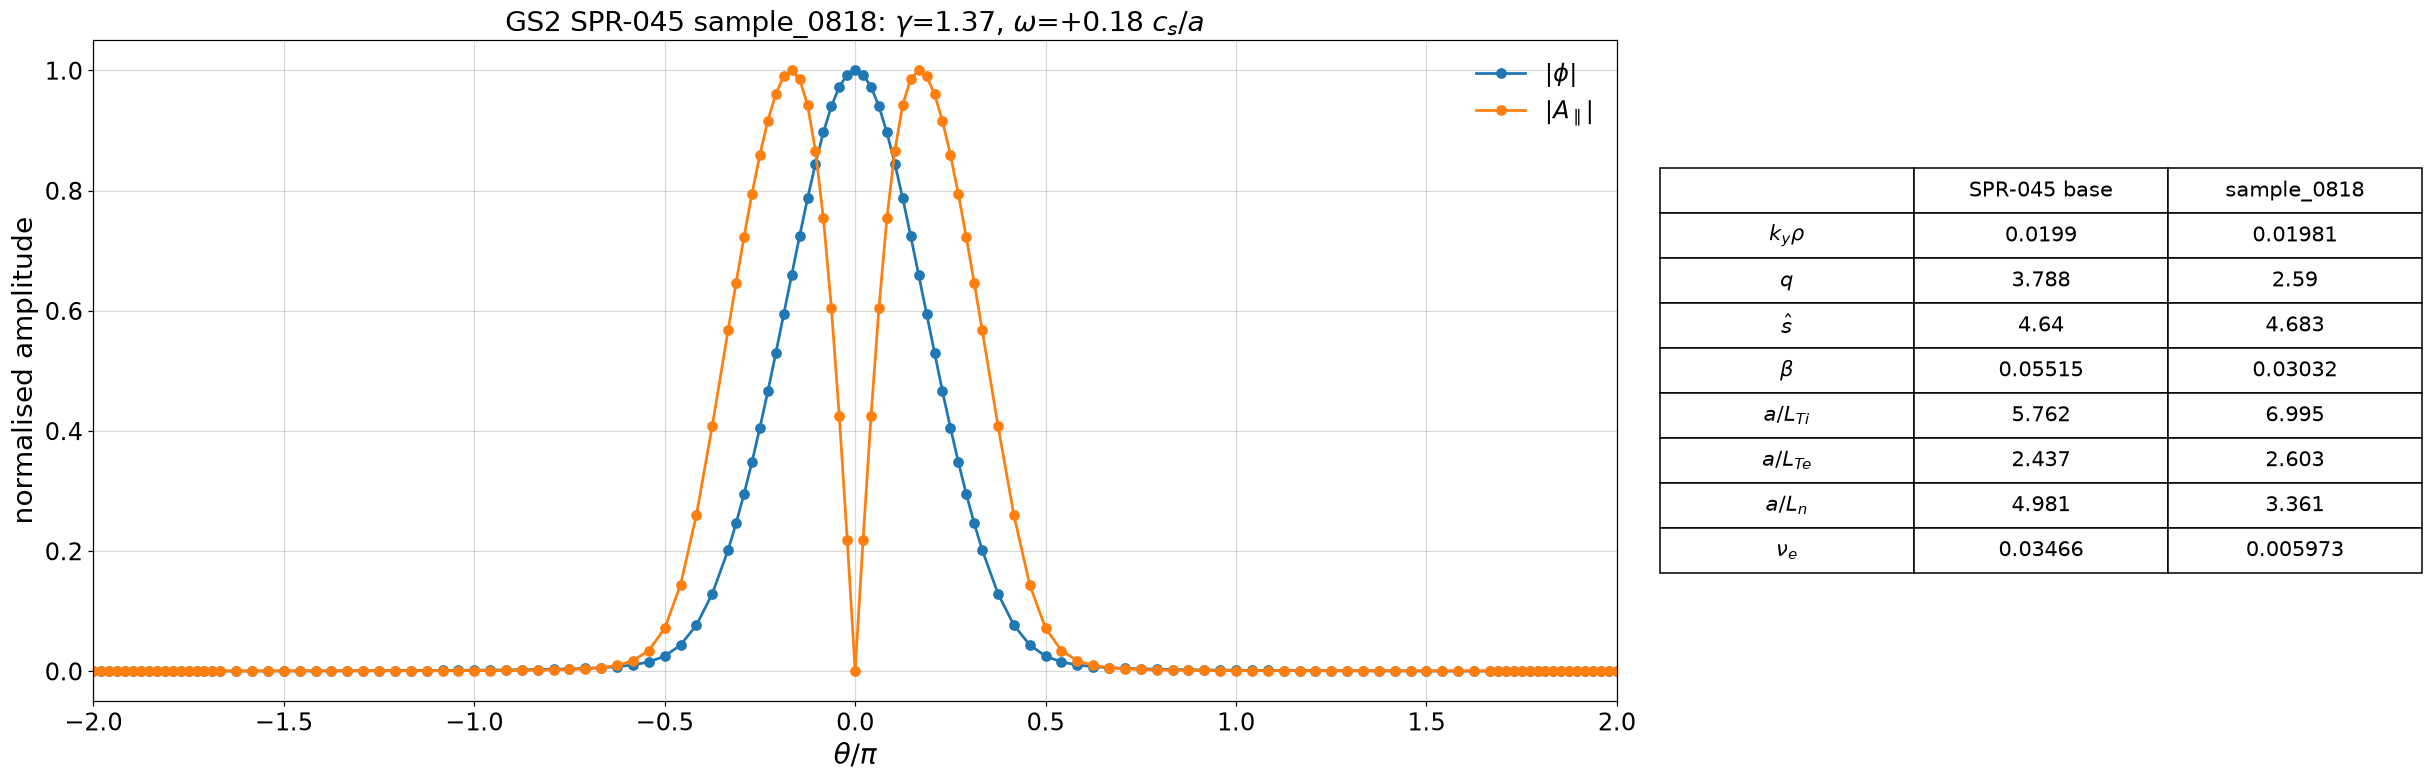

In [3]:
base = gs2_scan.base_pyro
base_species = base.local_species
base_values = dict(ky=base.numerics.ky.to(base.norms.pyrokinetics).m, q=base.local_geometry.q, shat=base.local_geometry.shat,
                   beta=base.numerics.beta.to(base.norms.pyrokinetics).m, ion_temp_gradient=base_species[base_species.names[0]].inverse_lt.m,
                   electron_temp_gradient=base_species.electron.inverse_lt.m, electron_dens_gradient=base_species.electron.inverse_ln.m,
                   electron_nu=base_species.electron.nu.to(base.norms.pyrokinetics).m)
parameter_labels = dict(ky=r"$k_y\rho$", q="$q$", shat=r"$\hat s$", beta=r"$\beta$", ion_temp_gradient="$a/L_{Ti}$",
                        electron_temp_gradient="$a/L_{Te}$", electron_dens_gradient="$a/L_n$", electron_nu=r"$\nu_e$")
parameters = pd.DataFrame({"base": {name: float(value) for name, value in base_values.items()}, sample: {name: float(gs2_output[name]) for name in base_values}})
print(parameters.round(4).to_string())

fig0, axes0 = plt.subplots(1, 2, figsize=(W, 0.35 * W), gridspec_kw={"width_ratios": [2, 1]})
for field, colour in (("phi", "C0"), ("apar", "C1")):
    amplitude = np.sqrt(gs2_power[field] / gs2_power[field].max())
    axes0[0].plot(amplitude.theta / np.pi, amplitude, color=colour, label=f"|{field_labels[field]}|")
axes0[0].set(xlabel=r"$\theta/\pi$", ylabel="normalised amplitude", xlim=(-2, 2))
axes0[0].set_title(rf"GS2 SPR-045 {sample}: $\gamma$={gamma_gs2:.2f}, $\omega$={omega_gs2:+.2f} $c_s/a$", fontsize=fs_title)
axes0[0].legend(fontsize=fs_legend)
axes0[1].axis("off")
cells = [[parameter_labels[name], f"{parameters.base[name]:.4g}", f"{parameters[sample][name]:.4g}"] for name in base_values]
table_artist = axes0[1].table(cellText=cells, colLabels=["", "SPR-045 base", sample], loc="center", cellLoc="center")
table_artist.set_fontsize(fs_legend)
table_artist.scale(1, 1.4)
plt.show()

## GFTM and TGLF leaves

One `PyroHypercube` per leaf. Each run's WIDTH and NBASIS_MAX are per-sample variables of the cube (GyroRun
`code_flags_per_sample`); the audit of `input.*.gen` (requested) against `out.*.localdump` / `out.tglf.globaldump`
(used) is in the Fusion_PhD README.

In [4]:
outputs, bpar_outputs = {}, {}
for arm, leaf in leaves.items():
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    Extent(scan.gk_output, fraction=fraction)
    outputs[arm] = scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)   # one ky per run
    bpar_scan = PyroHypercube(pyroscan_json=bpar_leaves[arm] / "pyroscan.json", load_base_pyro=True)
    bpar_scan.load_gk_output(netcdf_file=bpar_leaves[arm] / "pyroscan.nc")
    Extent(bpar_scan.gk_output, fraction=fraction)
    bpar_outputs[arm] = bpar_scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)   # one ky per run

rows = []
for arm, output in outputs.items():
    dominant_index = output.growth_rate.fillna(-np.inf).argmax("mode")
    dominant = output.isel(mode=dominant_index)
    bpar_extent = bpar_outputs[arm].extent.sel(field="bpar").isel(mode=dominant_index)
    gamma = dominant.growth_rate.clip(min=0).fillna(0).values
    unstable = gamma > 0
    rows.append(pd.DataFrame(dict(
        arm=arm, W=np.round(output.WIDTH.values.astype(float), 4), nb=output.NBASIS_MAX.values.astype(int), gamma=gamma,
        omega=np.where(unstable, dominant.mode_frequency.values, np.nan),
        **{f"extent_{field}": np.where(unstable, dominant.extent.sel(field=field).values, np.nan) for field in ["phi", "apar"]},
        extent_bpar=np.where(unstable, bpar_extent.values, np.nan), sample_index=np.arange(output.sizes["sample"]))))
table = pd.concat(rows, ignore_index=True).sort_values(["arm", "nb", "W"])
for field in fields:
    table[f"log_extent_ratio_{field}"] = np.log10(table[f"extent_{field}"] / extent_gs2[field])
widths = np.sort(table.W.unique())
print(table.groupby(["arm", "nb"]).size().unstack(), "\nwidths:", len(widths), widths.min(), "-", widths.max())
print("runs with no unstable mode:", table[table.gamma == 0].groupby(["arm", "nb"]).size().to_dict())

find_scan = PyroHypercube(pyroscan_json=find_width_leaf / "pyroscan.json", load_base_pyro=True)
find_scan.load_gk_output(netcdf_file=find_width_leaf / "pyroscan.nc")
find_output = find_scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)   # one ky per run
find_dominant = find_output.isel(mode=find_output.growth_rate.fillna(-np.inf).argmax("mode"))
# gaussian_width (pyro #616): the width TGLF's own search chose
find_width = pd.DataFrame(dict(nb_min=find_output.NBASIS_MIN.values.astype(int), W=find_dominant.gaussian_width.values,
                               gamma=find_dominant.growth_rate.values, omega=find_dominant.mode_frequency.values))
print("TGLF FIND_WIDTH T:\n", find_width.round(4).to_string(index=False))

nb      2     4     8     16    32    64
arm                                     
F     47.0  47.0  47.0  47.0  47.0  47.0
T     47.0  47.0  47.0  47.0  47.0  47.0
TGLF  47.0  47.0  47.0  47.0  47.0   NaN 
widths: 47 0.2 - 4.0
runs with no unstable mode: {('T', 2): 1, ('TGLF', 2): 2}


TGLF FIND_WIDTH T:
  nb_min      W  gamma  omega
      2 0.3507 2.7266 0.0815
      4 0.2648 2.7288 0.0939
      8 0.2000 2.7288 0.0956
     16 0.3194 2.7299 0.0917
     32 0.2412 2.7305 0.0944


## 4. Width selection against NBASIS

Analogue of qp5.24 fig2 / fig3 / fig3b for one mode. Per arm and NBASIS:
- $W_{\rm sel}(N) = \arg\max_W \gamma(W, N)$ (the max-$\gamma$ selection);
- $W_\gamma(N)$: the width whose $\gamma$ is closest to GS2 (an oracle);
- $W_{\rm ext}(N)$: the width whose $\phi$ extent is closest to GS2's (an oracle);
- TGLF's own FIND_WIDTH choice (stars, at NBASIS_MIN).

Middle: $\gamma$ at $W_{\rm sel}(N)$ against GS2. Right: $\phi$ extent ratio at $W_{\rm sel}(N)$.

 arm  nb  w_sel  w_gamma  w_ext  gamma_sel  omega_sel  log_extent_ratio_sel
   F   2 0.5279   0.3249 0.4000     2.4649     0.1173                0.1002
   F   4 0.4000   0.3031 0.3031     1.7511     0.1448                0.0776
   F   8 0.3031   0.5279 0.2297     1.5895     0.1576                0.0406
   F  16 0.2639   0.4287 0.5657     1.4489     0.1705                0.0207
   F  32 0.2000   0.2639 0.8000     1.3823     0.1787                0.0100
   F  64 0.2000   0.2000 1.2000     1.3484     0.1813                0.0084
   T   2 0.4000   0.4000 0.4000     1.1842     0.1739               -0.0098
   T   4 0.4000   0.4000 0.3732     1.3016     0.1828                0.0075
   T   8 0.4595   0.4595 0.3732     1.3121     0.1880                0.0052
   T  16 0.4595   0.4595 0.2297     1.3291     0.1860                0.0054
   T  32 0.6063   0.6063 0.2000     1.3381     0.1840                0.0069
   T  64 0.4595   0.4595 0.2000     1.3352     0.1842                0.0066
TGLF   2 0.3

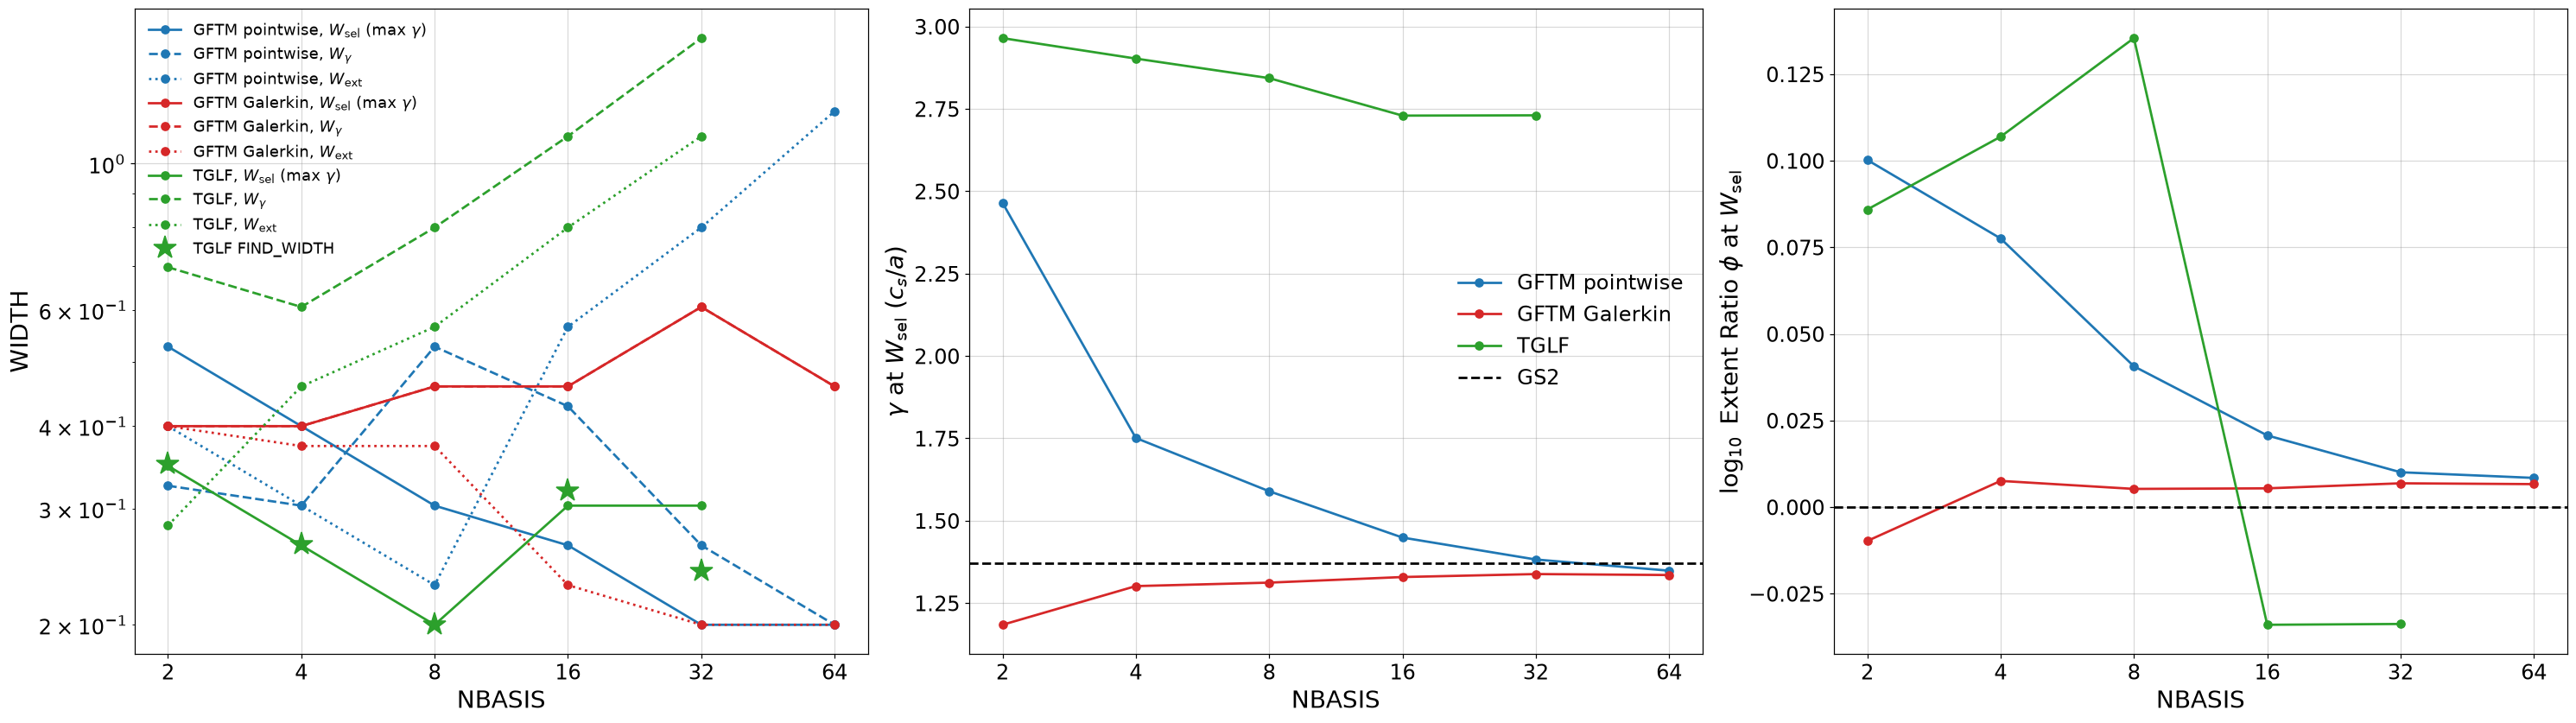

In [10]:
rows = []
for (arm, nb), a in table.groupby(["arm", "nb"]):
    a = a.reset_index(drop=True)
    pick = int(a.gamma.idxmax())
    rows.append(dict(arm=arm, nb=nb, w_sel=a.W[pick], w_gamma=a.W[(a.gamma - gamma_gs2).abs().idxmin()],
                     w_ext=a.W[a.log_extent_ratio_phi.abs().idxmin()], gamma_sel=a.gamma[pick], omega_sel=a.omega[pick],
                     log_extent_ratio_sel=a.log_extent_ratio_phi[pick]))
selection = pd.DataFrame(rows)
print(selection.round(4).to_string(index=False))

fig4, axes4 = plt.subplots(1, 3, figsize=(W, 0.33 * W), squeeze=False)
for arm in arms:
    d = selection[selection.arm == arm].sort_values("nb")
    for column, ls, label in (("w_sel", "-", r"$W_{\rm sel}$ (max $\gamma$)"), ("w_gamma", "--", r"$W_\gamma$"), ("w_ext", ":", r"$W_{\rm ext}$")):
        axes4[0, 0].plot(d.nb, d[column], color=arm_colours[arm], ls=ls, marker="o", label=f"{arms[arm]}, {label}")
    axes4[0, 1].plot(d.nb, d.gamma_sel, color=arm_colours[arm], marker="o", label=arms[arm])
    axes4[0, 2].plot(d.nb, d.log_extent_ratio_sel, color=arm_colours[arm], marker="o", label=arms[arm])
axes4[0, 0].plot(find_width.nb_min, find_width.W, ls="", marker="*", ms=8, color=arm_colours["TGLF"], label="TGLF FIND_WIDTH")
axes4[0, 1].axhline(gamma_gs2, color="k", ls="--", marker="", label="GS2")
axes4[0, 2].axhline(0, color="k", ls="--", marker="", label="GS2")
for ax, ylabel in zip(axes4[0], ["WIDTH", r"$\gamma$ at $W_{\rm sel}$ ($c_s/a$)", r"$\log_{10}$ Extent Ratio $\phi$ at $W_{\rm sel}$"]):
    ax.set(xscale="log", xlabel="NBASIS", ylabel=ylabel)
    log_xticks(ax, nbasis_all)
axes4[0, 0].set_yscale("log")
axes4[0, 0].legend(ncol=1)
axes4[0, 1].legend(fontsize=fs_legend)
plt.show()

In [12]:
out = ROOT / "Plots/TGLF_GFTM_KBM_PAPER" / analysis_name   # `make figures` in Papers copies the PDFs from here
out.mkdir(parents=True, exist_ok=True)
for name, fig in (
                  ("tglf_gftm_selected_width_and_gamma_and_extent_ratio_vs_nbasis", fig4),
                  ):
    fig.savefig(out / f"{analysis_name}_{name}.pdf")   # exact size, no tight bbox
selection.round(4).to_csv(out / "width_selection.csv", index=False)
parameters.round(5).to_csv(out / "sample_vs_base_parameters.csv")
print(sorted(p.name for p in out.iterdir()))